# Whole-tooth segmentation: empirical review

Clinical severity/actionable-case labels are unavailable. All reported NPV/AUROC and false-negative quantities below concern tooth/background pixels, not clinical triage outcomes. This notebook reads completed results and does not retrain or retune a model.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
root = Path.cwd()
assert (root / "per_image.csv").exists(), "Run this notebook from the study_results directory."
print("Result directory:", root.name)


Result directory: study_results


In [2]:
summary = pd.read_csv(root / "metric_summary.csv")
clean_dice = summary[(summary.corruption == "clean") & (summary.metric == "dice")]
print(clean_dice[["model", "mean", "lower", "upper", "n"]].to_string(index=False))


               model     mean    lower    upper  n
        segformer_b0 0.877574 0.871334 0.883392 66
unet_efficientnet_b0 0.888367 0.881815 0.894454 66
       unet_resnet34 0.901166 0.895996 0.906053 66


In [3]:
audit = pd.read_csv(root / "failure_audit/pixel_and_boundary_summary.csv")
clean_pixel = audit[(audit.corruption == "clean") & audit.metric.isin(["pixel_npv", "pixel_auroc", "boundary_f1_2px"])]
print(clean_pixel[["model", "metric", "mean", "lower", "upper"]].to_string(index=False))
print("These are segmentation pixel/boundary metrics, not actionable-case diagnostic metrics.")


               model          metric     mean    lower    upper
        segformer_b0       pixel_npv 0.984569 0.983193 0.985916
        segformer_b0     pixel_auroc 0.993166 0.992593 0.993758
        segformer_b0 boundary_f1_2px 0.791466 0.779101 0.804088
unet_efficientnet_b0       pixel_npv 0.985646 0.984162 0.987010
unet_efficientnet_b0     pixel_auroc 0.992165 0.991140 0.993058
unet_efficientnet_b0 boundary_f1_2px 0.818838 0.806198 0.831253
       unet_resnet34       pixel_npv 0.987036 0.985625 0.988349
       unet_resnet34     pixel_auroc 0.993837 0.993149 0.994461
       unet_resnet34 boundary_f1_2px 0.855357 0.845207 0.865800
These are segmentation pixel/boundary metrics, not actionable-case diagnostic metrics.


In [4]:
fn = audit[(audit.severity == 3) & (audit.metric == "foreground_fn_fraction")]
print(fn[["model", "corruption", "mean", "lower", "upper"]].to_string(index=False))
status = pd.read_csv(root / "failure_audit/clinical_triage_estimability.csv")
assert status.status.eq("not_estimable").all()
print("Clinical triage estimability:", status.status.unique().tolist())


               model     corruption     mean    lower    upper
        segformer_b0  gaussian_blur 0.153883 0.138492 0.168639
        segformer_b0 gaussian_noise 0.148856 0.139796 0.157819
        segformer_b0    motion_blur 0.299817 0.267054 0.333678
        segformer_b0     resolution 0.232820 0.210197 0.256156
        segformer_b0  underexposure 0.179627 0.163327 0.195791
unet_efficientnet_b0  gaussian_blur 0.172304 0.157395 0.186897
unet_efficientnet_b0 gaussian_noise 0.193318 0.177823 0.209474
unet_efficientnet_b0    motion_blur 0.219667 0.198376 0.240145
unet_efficientnet_b0     resolution 0.313679 0.289355 0.338901
unet_efficientnet_b0  underexposure 0.183250 0.168084 0.199250
       unet_resnet34  gaussian_blur 0.105535 0.094312 0.116670
       unet_resnet34 gaussian_noise 0.130957 0.121795 0.140572
       unet_resnet34    motion_blur 0.139804 0.124104 0.155436
       unet_resnet34     resolution 0.158950 0.141666 0.176740
       unet_resnet34  underexposure 0.163604 0.149138 0

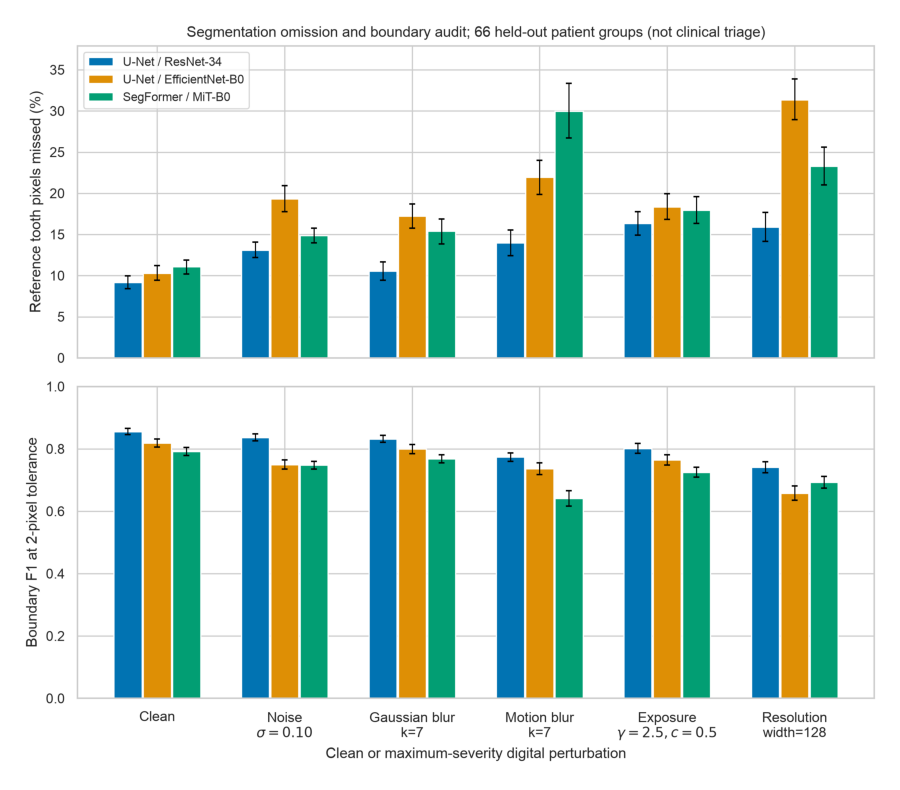

In [5]:
figure = plt.figure(figsize=(10, 8))
plt.imshow(plt.imread(root / "failure_audit/figure4_segmentation_fn_boundary.png"))
plt.axis("off")
plt.tight_layout()
figure


## Provenance and declarations

The test cohort and trained checkpoints remain frozen. The boundary/false-negative extension is post hoc; selected worst-case visual panels are illustrative, not a population safety estimate. Exemption eligibility is the investigator's stated basis and formal institutional confirmation remains pending. Public code release is planned upon publication, not already completed.